# EMQA_L3_rv_solar

**Relative intraday variation of the Romanian day-ahead price (realised variation of hourly prices divided by the daily price, monthly median) and mean Romanian solar generation (monthly mean, MW), 2019-01-01 to 2026-10-31: solar generation has made the price move more within the day.**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_rv_solar/EMQA_L3_rv_solar.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## Intraday variation and solar generation

$RV_d=\sqrt{\sum_h (P_{d,h}-P_{d,h-1})^2}$ over the hours of delivery day $d$; relative variation $RV_d/|\bar P_d|$, with $\bar P_d$ the mean hourly price of the day.

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# hourly prices of Romania (15-min MTUs averaged to the hour from 1 Oct 2025), CET/CEST clock
HP = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', usecols=['timestamp_utc', 'RO'], parse_dates=['timestamp_utc']).set_index('timestamp_utc')['RO']
HP.index = HP.index.tz_convert('Europe/Brussels')
HP = HP.dropna().loc[str(START.date()):str(END.date())]
# intraday variation RV_d = sqrt(sum_h (P_{d,h} - P_{d,h-1})^2), within the delivery day
_h = pd.DataFrame({'p': HP.values, 'day': HP.index.tz_localize(None).normalize()})
_h['dp'] = _h.groupby('day')['p'].diff()
_gh = _h.groupby('day')
RV = pd.DataFrame({'rv': np.sqrt(_gh['dp'].apply(lambda x: (x ** 2).sum(min_count=1))), 'lvl': _gh['p'].mean()}).reindex(CAL)
print('days with RV:', int(RV['rv'].notna().sum()), 'of', len(CAL))

days with RV: 2861 of 2861


In [5]:
GEN = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'solar'], parse_dates=['date_cet']).set_index('date_cet')
SOL = GEN['solar'].reindex(CAL)
RV['rel'] = RV['rv'] / RV['lvl'].abs()

### Numbers on the slide

In [6]:
YEARS = list(range(START.year, END.year + 1))
rel = {y: round(RV['rel'][RV.index.year == y].median(), 2) for y in YEARS}
for y in YEARS:
    slide(f'median relative intraday variation, {y}', f'rv.rel_by_year.{y}', rel[y])
slide('year of the peak', 'rv.rel_peak_year', max(YEARS, key=lambda y: rel[y]))
slide('mean solar output 2019, MW', 'rv.sol_2019', SOL[SOL.index.year == 2019].mean(), 0)
slide(f'mean solar output {END.year} (to the cut-off), MW', 'rv.sol_last', SOL[SOL.index.year == END.year].mean(), 0)
mm = pd.DataFrame({'rel': RV['rel'].resample('MS').median(), 'sol': SOL.resample('MS').mean()}).dropna()
slide('monthly correlation', 'rv.corr_rel_solar_m', np.corrcoef(mm['rel'], mm['sol'])[0, 1], 2)

median relative intraday variation, 2019                   0.64   [rv.rel_by_year.2019]
median relative intraday variation, 2020                   0.6   [rv.rel_by_year.2020]
median relative intraday variation, 2021                   0.55   [rv.rel_by_year.2021]
median relative intraday variation, 2022                   0.65   [rv.rel_by_year.2022]
median relative intraday variation, 2023                   0.96   [rv.rel_by_year.2023]
median relative intraday variation, 2024                   1.24   [rv.rel_by_year.2024]
median relative intraday variation, 2025                   1.18   [rv.rel_by_year.2025]
median relative intraday variation, 2026                   1.01   [rv.rel_by_year.2026]
year of the peak                                           2024   [rv.rel_peak_year]
mean solar output 2019, MW                                 157.0   [rv.sol_2019]
mean solar output 2026 (to the cut-off), MW                593.0   [rv.sol_last]
monthly correlation                               

### Chart

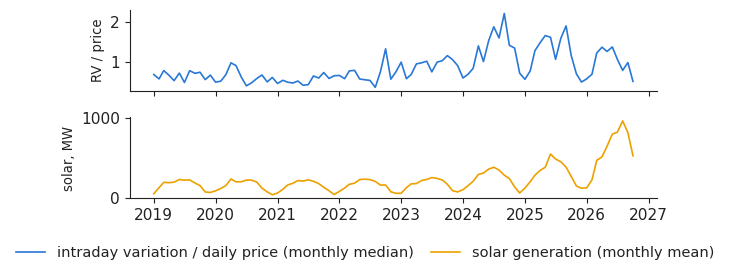

In [7]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
MON = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


def yfmt(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


def mfmt(ax, step=1):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=step))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: MON[mdates.num2date(v).month - 1] +
                                               (f'\n{mdates.num2date(v).year}' if mdates.num2date(v).month == 1 else '')))
fig, axs = plt.subplots(2, 1, figsize=(6.4, 2.8), sharex=True)
rm = RV['rel'].resample('MS').median()
axs[0].plot(rm.index, rm.values, color=PAL['RO'], lw=1.2)
axs[0].set_ylabel('RV / price', fontsize=9.5)
sm_ = SOL.resample('MS').mean()
axs[1].plot(sm_.index, sm_.values, color=PAL['BG'], lw=1.2)
axs[1].set_ylabel('solar, MW', fontsize=9.5)
yfmt(axs[1])
legend_bottom(fig, handles=[plt.Line2D([], [], color=PAL['RO'], lw=1.2), plt.Line2D([], [], color=PAL['BG'], lw=1.2)],
              labels=['intraday variation / daily price (monthly median)', 'solar generation (monthly mean)'], ncol=2)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.savefig('rv_solar.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()